In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!ls -lh /content/drive/MyDrive/*.zip

-rw------- 1 root root 980M May 10  2026 '/content/drive/MyDrive/Basketball_Project-main (2).zip'
-rw------- 1 root root 2.9G Nov 21 16:33  /content/drive/MyDrive/D-Fire.zip


In [5]:
!unzip -q "/content/drive/MyDrive/D-Fire.zip" -d /content/dfire
print("Done!")

Done!


In [6]:
!find /content/dfire -maxdepth 3 -type d

/content/dfire
/content/dfire/train
/content/dfire/train/labels
/content/dfire/train/images
/content/dfire/test
/content/dfire/test/labels
/content/dfire/test/images


In [7]:
import glob

for folder in sorted(glob.glob("/content/dfire/**/images", recursive=True)):
    n_images = len(glob.glob(folder + "/*"))
    n_labels = len(glob.glob(folder.replace("images", "labels") + "/*.txt"))
    print(f"{folder}:  {n_images} images, {n_labels} label files")

/content/dfire/test/images:  4306 images, 4306 label files
/content/dfire/train/images:  17221 images, 17221 label files


In [8]:
import glob
from collections import Counter

CLASS_NAMES = {0: "smoke", 1: "fire"}   # D-Fire's class numbers

def dataset_stats(split):
    label_files = glob.glob(f"/content/dfire/{split}/labels/*.txt")
    box_counts = Counter()        # how many boxes of each class
    image_types = Counter()       # what each image contains

    for path in label_files:
        with open(path) as f:
            lines = [line for line in f if line.strip()]   # skip empty lines
        classes = {int(line.split()[0]) for line in lines}  # set of classes in this image

        for line in lines:
            box_counts[CLASS_NAMES[int(line.split()[0])]] += 1

        if not classes:
            image_types["nothing (negative)"] += 1
        elif classes == {1}:
            image_types["fire only"] += 1
        elif classes == {0}:
            image_types["smoke only"] += 1
        else:
            image_types["fire + smoke"] += 1

    print(f"=== {split.upper()} ({len(label_files)} images) ===")
    print("Images:", dict(image_types))
    print("Boxes: ", dict(box_counts))
    print()

dataset_stats("train")
dataset_stats("test")

=== TRAIN (17221 images) ===
Images: {'nothing (negative)': 7833, 'smoke only': 4681, 'fire + smoke': 3763, 'fire only': 944}
Boxes:  {'smoke': 9550, 'fire': 11814}

=== TEST (4306 images) ===
Images: {'nothing (negative)': 2005, 'fire + smoke': 895, 'fire only': 220, 'smoke only': 1186}
Boxes:  {'smoke': 2315, 'fire': 2878}



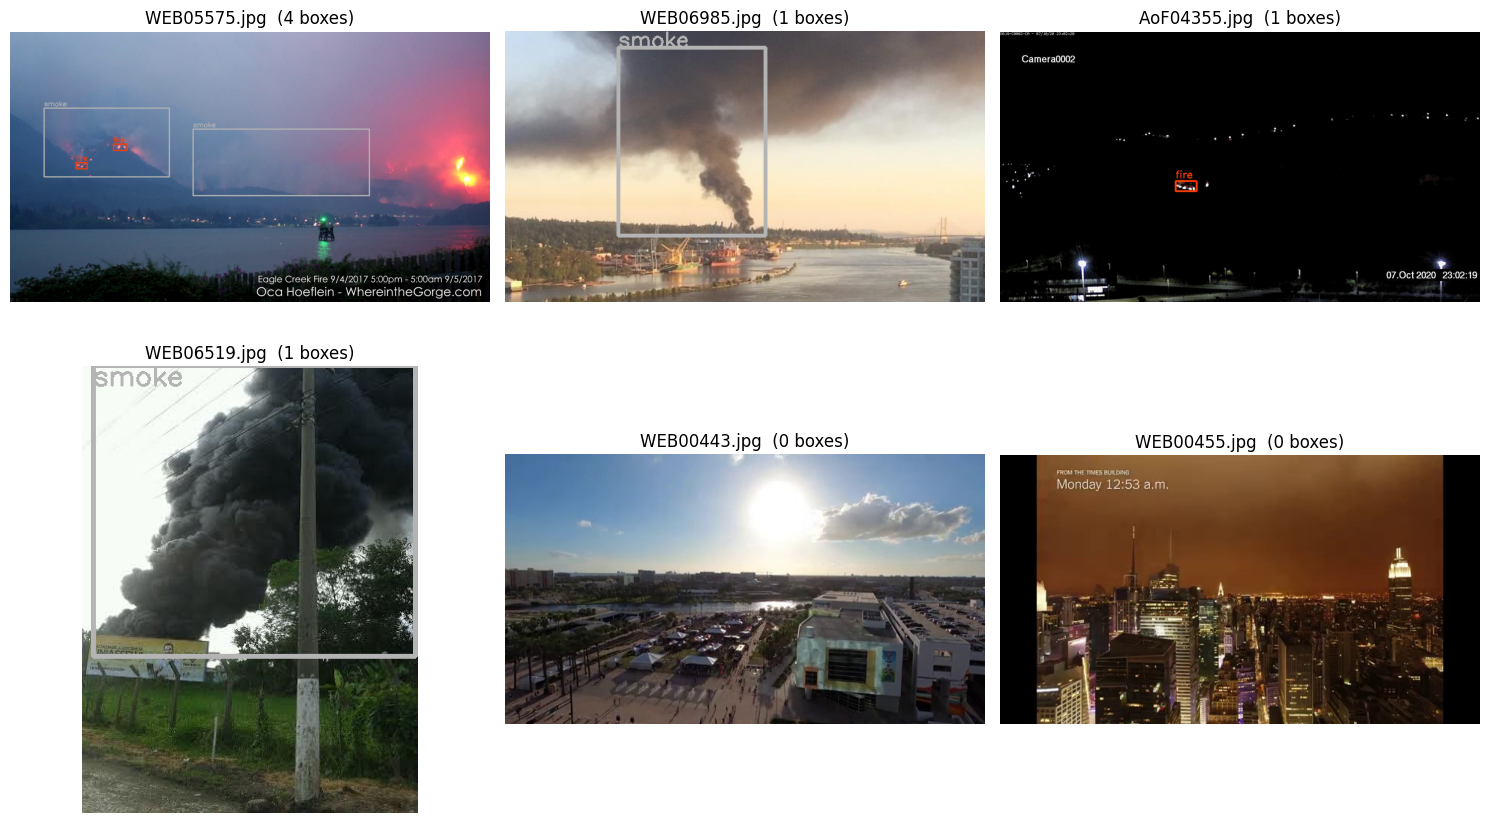

In [9]:
import random
import cv2
import matplotlib.pyplot as plt

COLORS = {0: (180, 180, 180), 1: (255, 60, 0)}   # smoke = grey, fire = orange-red (RGB)

def show_examples(split="train", n=6, seed=None):
    random.seed(seed)
    image_paths = random.sample(glob.glob(f"/content/dfire/{split}/images/*"), n)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    for ax, img_path in zip(axes.flat, image_paths):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)  # OpenCV loads BGR -> convert to RGB
        h, w = img.shape[:2]                                         # image height and width in pixels

        label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        with open(label_path) as f:
            lines = [l.split() for l in f if l.strip()]

        for cls, xc, yc, bw, bh in lines:
            cls = int(cls)
            # YOLO format (fractions, centre) -> pixel corners
            xc, yc, bw, bh = float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h
            x1, y1 = int(xc - bw / 2), int(yc - bh / 2)
            x2, y2 = int(xc + bw / 2), int(yc + bh / 2)
            cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[cls], 3)
            cv2.putText(img, CLASS_NAMES[cls], (x1, max(y1 - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, COLORS[cls], 2)

        ax.imshow(img)
        ax.set_title(f"{img_path.split('/')[-1]}  ({len(lines)} boxes)")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_examples("train")

In [10]:
import os, random, shutil, glob

random.seed(42)   # fixed seed = same random split every time (reproducible)

train_imgs = sorted(glob.glob("/content/dfire/train/images/*"))
val_imgs = random.sample(train_imgs, int(0.15 * len(train_imgs)))   # pick 15% at random

os.makedirs("/content/dfire/val/images", exist_ok=True)
os.makedirs("/content/dfire/val/labels", exist_ok=True)

for img in val_imgs:
    name = os.path.splitext(os.path.basename(img))[0]          # "WEB00443.jpg" -> "WEB00443"
    shutil.move(img, "/content/dfire/val/images/")              # move the image
    shutil.move(f"/content/dfire/train/labels/{name}.txt",      # move its label too
                "/content/dfire/val/labels/")

for split in ["train", "val", "test"]:
    print(split, len(os.listdir(f"/content/dfire/{split}/images")), "images")

train 14638 images
val 2583 images
test 4306 images


In [11]:
yaml_text = """
path: /content/dfire
train: train/images
val: val/images
test: test/images

names:
  0: smoke
  1: fire
"""

with open("/content/fire.yaml", "w") as f:
    f.write(yaml_text)

print(open("/content/fire.yaml").read())


path: /content/dfire
train: train/images
val: val/images
test: test/images

names:
  0: smoke
  1: fire



In [13]:
!pip install -q ultralytics

In [14]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
model.train(
    data="/content/fire.yaml",
    epochs=1,          # just one pass
    fraction=0.05,     # use only 5% of the training images
    imgsz=640,
    project="/content/drive/MyDrive/fire_runs",   # save results to Google Drive
    name="test_run",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d6829747ed0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [15]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data="/content/fire.yaml",
    epochs=40,          # 40 full passes over the training data
    patience=10,        # stop early if val score hasn't improved for 10 epochs
    imgsz=640,          # images resized to 640 px
    batch=-1,           # let YOLO pick the largest batch that fits in GPU memory
    hsv_h=0.005,        # keep colour-shift augmentation tiny (see below)
    project="/content/drive/MyDrive/fire_runs",
    name="yolo26n_fire",
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_fire, nbs=64, nms=None, opset=None, optimize=False, optimizer=

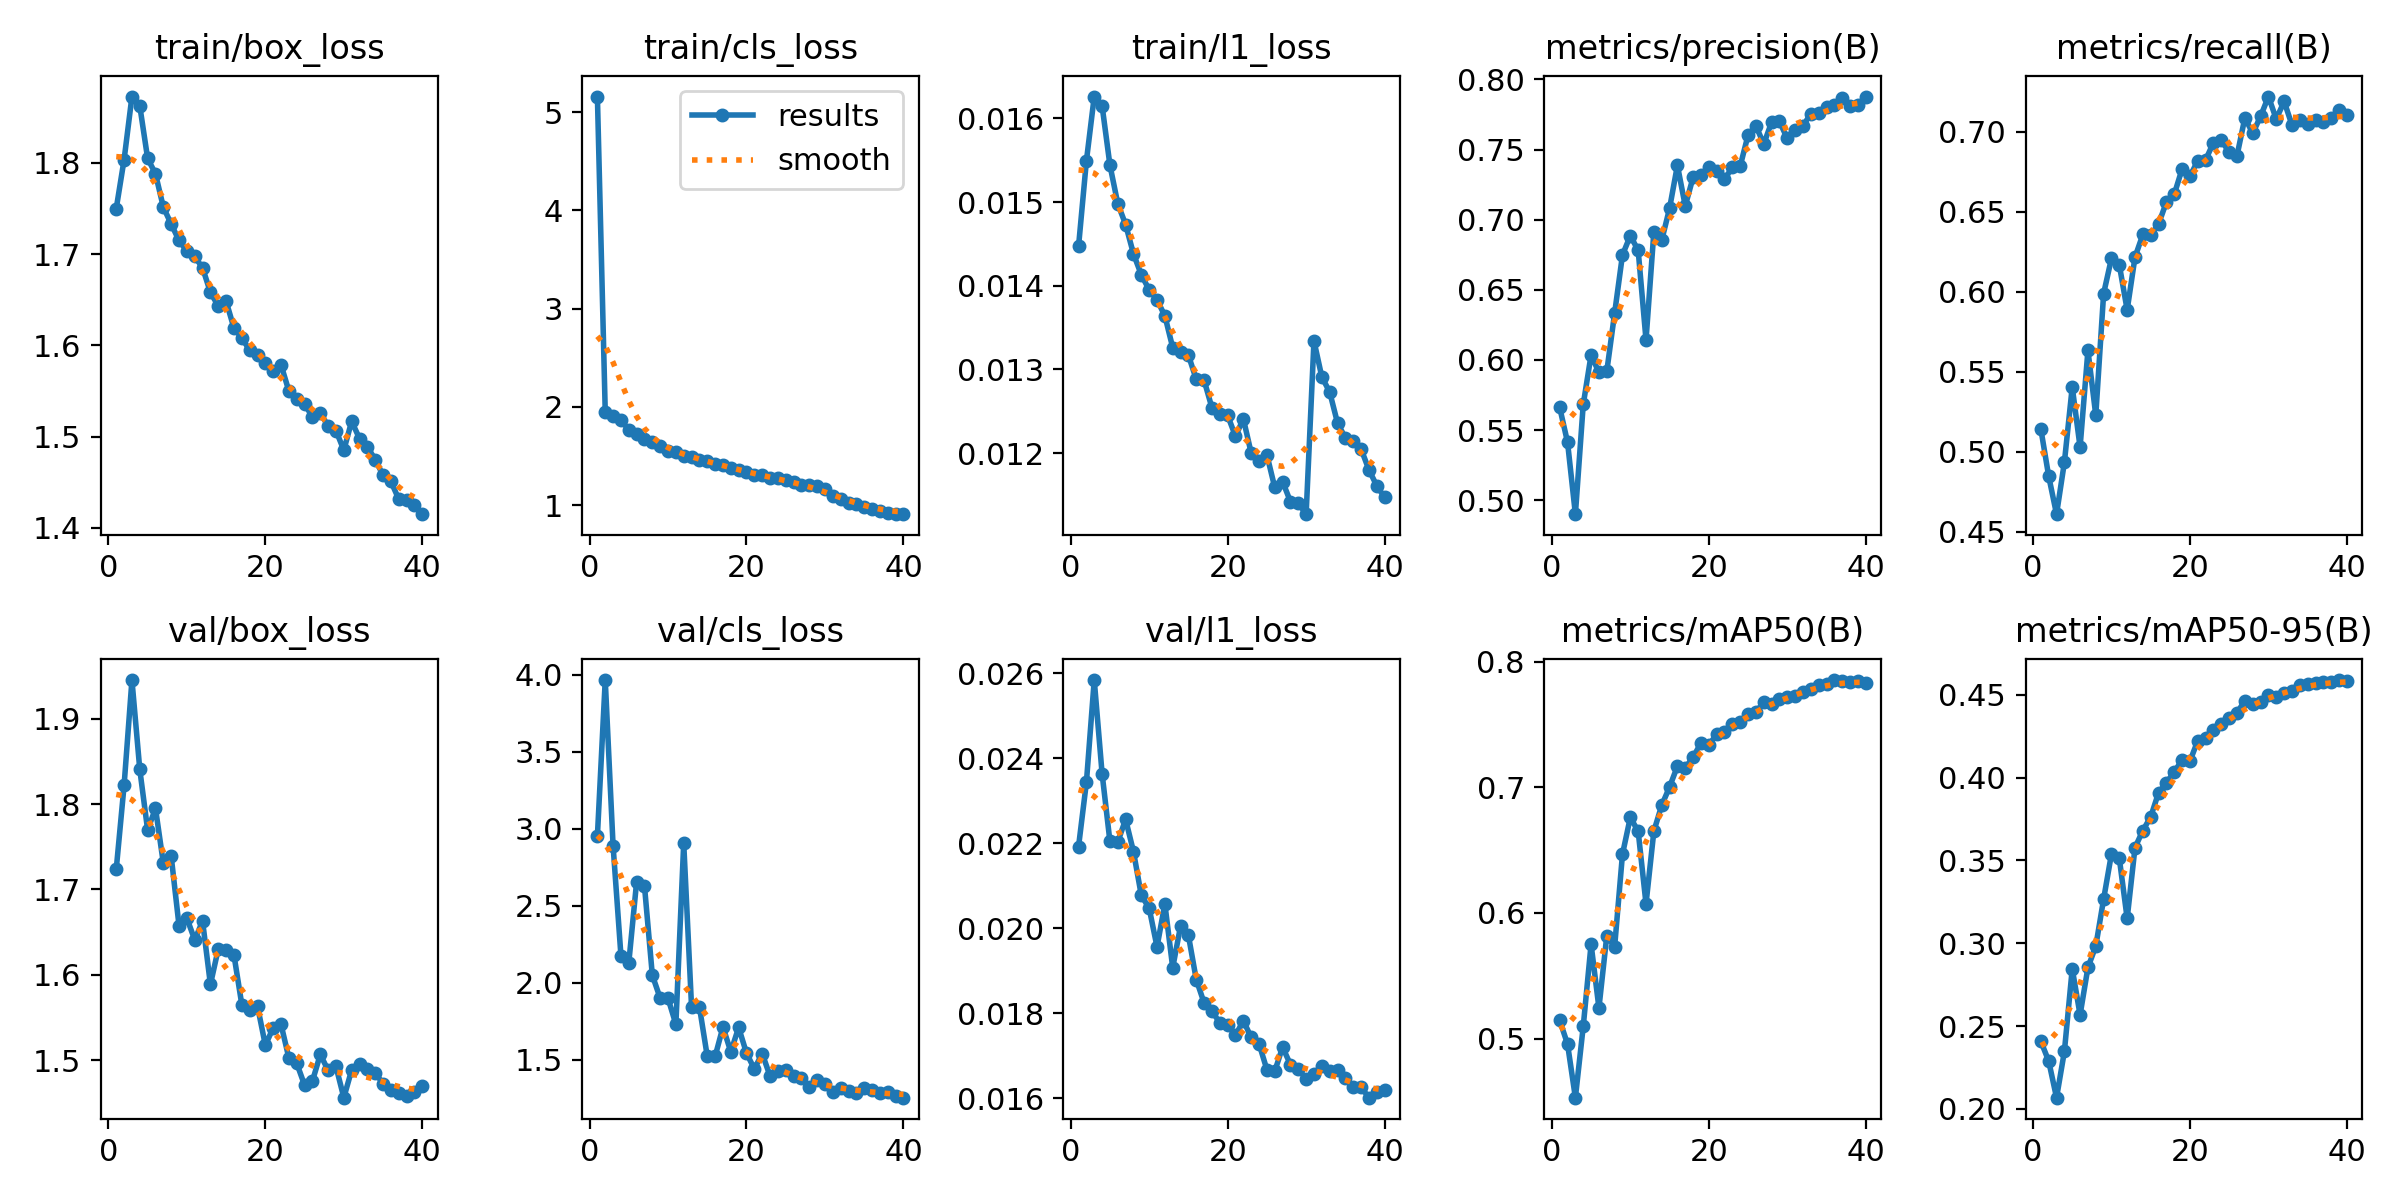

In [16]:
from IPython.display import Image, display

RUN = "/content/drive/MyDrive/fire_runs/yolo26n_fire"
display(Image(f"{RUN}/results.png", width=1100))

In [17]:
from ultralytics import YOLO

model = YOLO(f"{RUN}/weights/best.pt")

metrics = model.val(
    data="/content/fire.yaml",
    split="test",          # the "real exam": images never used for any decision
    project=RUN,
    name="test_eval",
)

print("\n| Class | Precision | Recall | mAP50 | mAP50-95 |")
print("|---|---|---|---|---|")
for i, cls_id in enumerate(metrics.box.ap_class_index):
    p, r, ap50, ap = metrics.box.class_result(i)
    print(f"| {model.names[int(cls_id)]} | {p:.3f} | {r:.3f} | {ap50:.3f} | {ap:.3f} |")
print(f"| **all** | {metrics.box.mp:.3f} | {metrics.box.mr:.3f} | {metrics.box.map50:.3f} | {metrics.box.map:.3f} |")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 33.9±29.0 MB/s, size: 103.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dfire/test/labels... 4306 images, 2005 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 592.7it/s 7.3s
val: /content/dfire/test/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /content/dfire/test/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /content/dfire/test/images/WEB11243.jpg: corrupt JPEG restored and saved
val: /content/dfire/test/images/WEB11244.jpg: corrupt JPEG restored and saved
val: /content/dfire/test/images/WEB11245.jpg: co

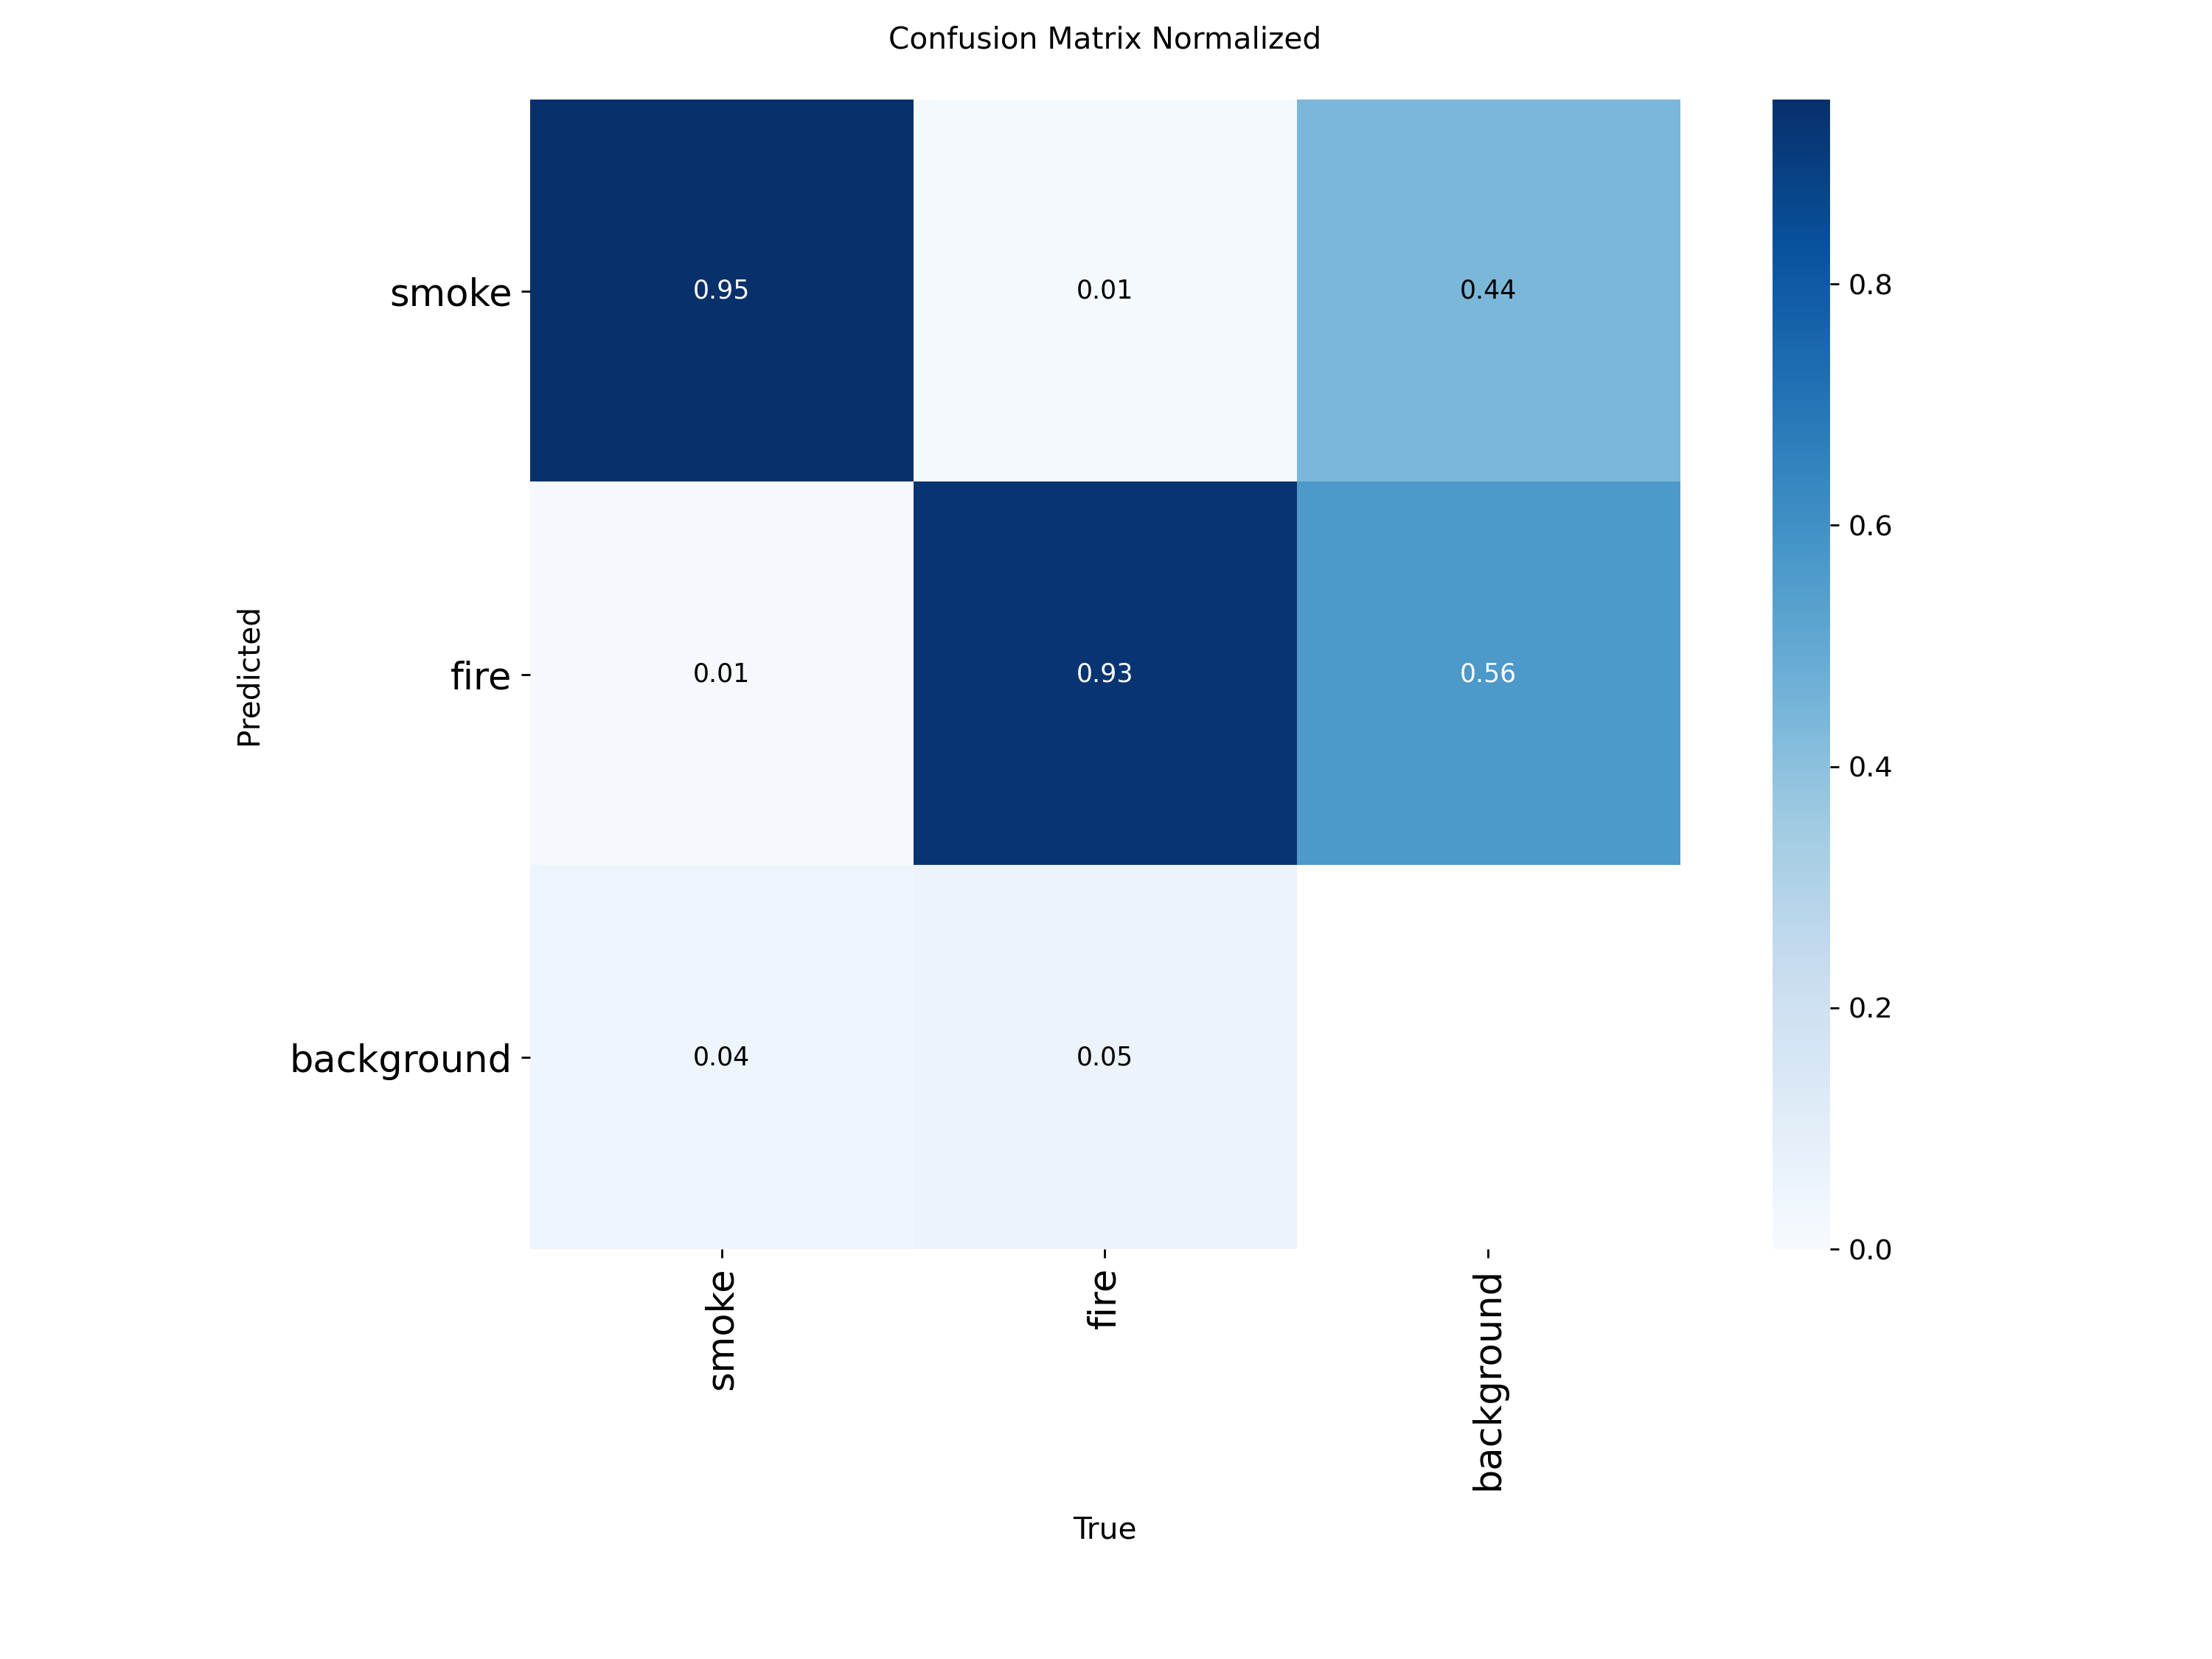

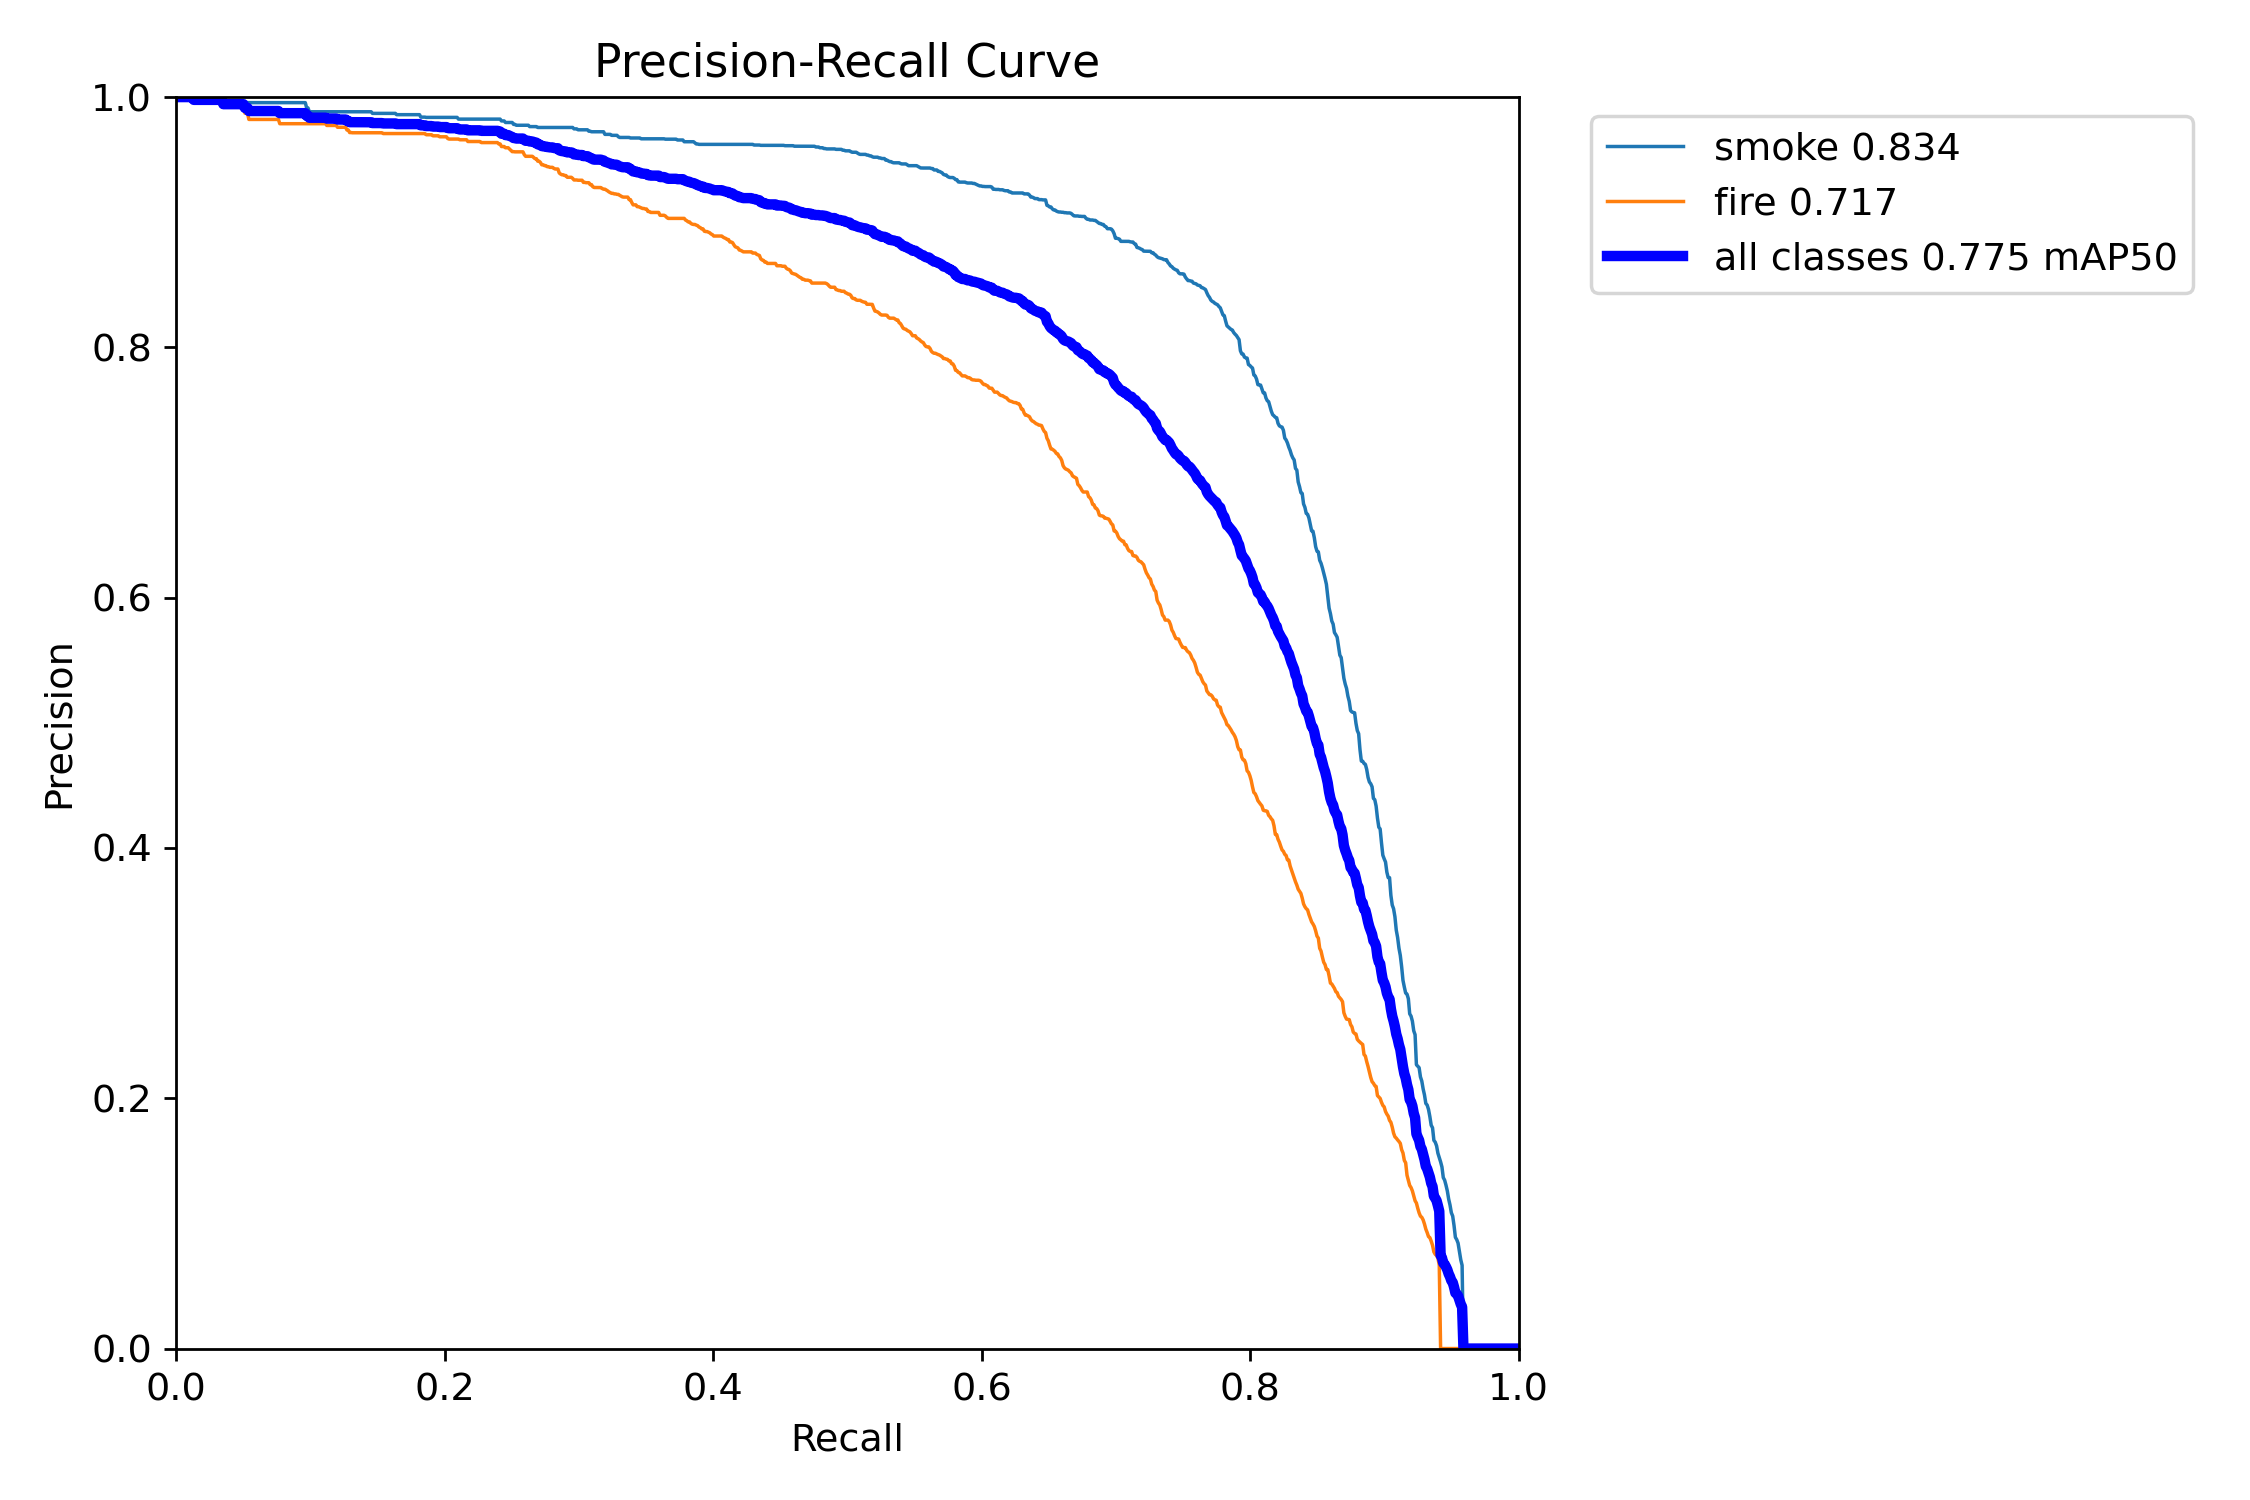

In [18]:
display(Image(f"{RUN}/test_eval/confusion_matrix_normalized.png", width=650))
display(Image(f"{RUN}/test_eval/BoxPR_curve.png", width=650))

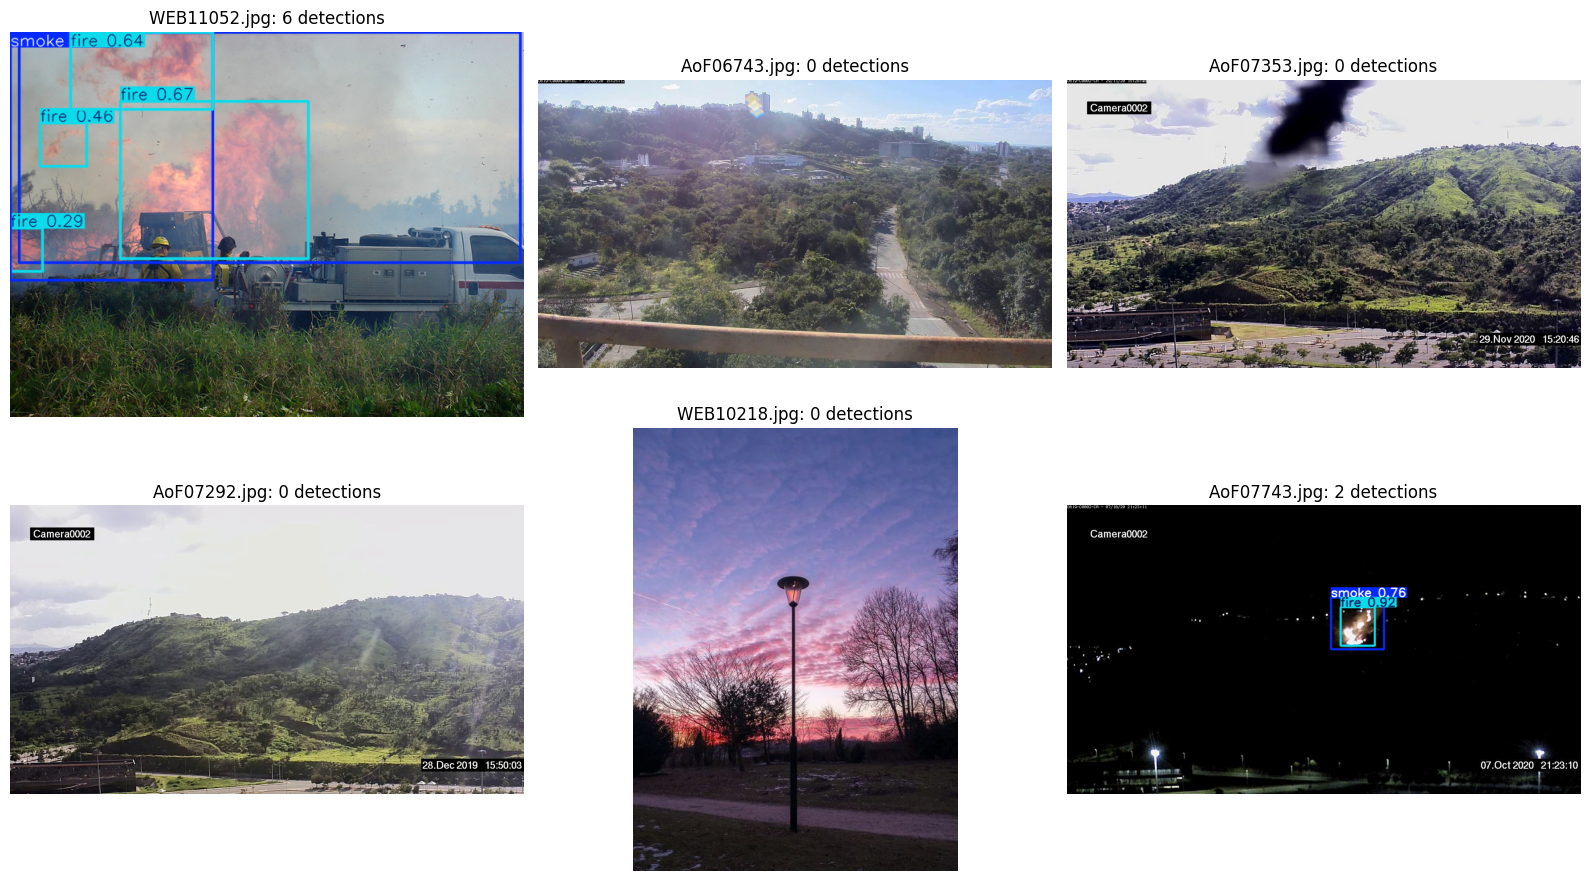

In [21]:
import random, glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO(f"{RUN}/weights/best.pt")
test_imgs = random.sample(glob.glob("/content/dfire/test/images/*"), 6)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, path in zip(axes.flat, test_imgs):
    result = model(path, conf=0.25, verbose=False)[0]
    ax.imshow(result.plot()[:, :, ::-1])     # plot() draws boxes (BGR) -> flip to RGB
    ax.set_title(f"{path.split('/')[-1]}: {len(result.boxes)} detections")
    ax.axis("off")
plt.tight_layout()
plt.show()